# User
yes

In [ ]:


# Importowanie popularnych bibliotek
!pip install --upgrade pip
!pip install feature-engine --user
!pip install minisom  


import numpy as np             # Obsługa tablic i operacji matematycznych
import pandas as pd            # Analiza i manipulacja danymi
import seaborn as sns          # Wizualizacja danych
import matplotlib.pyplot as plt  # Tworzenie wykresów
from sklearn import datasets   # Narzędzia z biblioteki scikit-learn
from feature_engine import imputation  # Operacje na cechach
import scipy as sp             # Obliczenia naukowe
from minisom import MiniSom    # Samoorganizujące się mapy (SOM)

!pip list | grep minisom








  Using cached pip-25.0.1-py3-none-any.whl.metadata (3.7 kB)
Using cached pip-25.0.1-py3-none-any.whl (1.8 MB)


ERROR: To modify pip, please run the following command:
C:\Users\XYZ\anaconda3\python.exe -m pip install --upgrade pip


'grep' is not recognized as an internal or external command,
operable program or batch file.


In [ ]:
#Dodatkowe "ułatwienia" w ustawieniach wyświetlania
import 
# Wyłączenie ramki wyświetlania (jeśli nam przeszkadza)
from IPython.display import display, HTML
display(HTML("<style>.output_scroll { height: auto !important; }</style>"))

# Wyłączenie ostrzeżeń dla analizy k-średnich
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)


### Jupyter - ułatwienia w pracy, pisaniu kodu

**Automatyczne uzupełnianie kodu (Tab)** <BR>
* Wpisz początek funkcji/zmiennej i naciśnij Tab

**Podpowiedzi argumentów funkcji (Shift + Tab)**
* Wpisz nazwę funkcji i otwórz nawias, a następnie naciśnij Shift + Tab
* Jeśli chcesz więcej szczegółów, naciśnij Shift + Tab większą liczbę razy.
    
**Wywołanie dokumentacji (?)**
* Dodaj ? przed lub po funkcji, aby zobaczyć dokumentację
    
**Pełne podświetlanie składni i podpowiedzi (Jupyter Lab)**
    
* pip install jupyterlab-lsp python-lsp-server


## Pierwszy przykład analizy
### Wykonamy krok po kroku kolejne kroki związane z:

1. **Importem danych**
2. **Zrozumieniem danych**
3. **Czyszczeniem danych**
4. **Budową modelu**
5. **Oceną modeu**
6. **Interpretacją modelu**

In [76]:
#Dodatkowe "ułatwienia" w ustawieniach wyświetlania
#import 
# Wyłączenie ramki wyświetlania (jeśli nam przeszkadza)
from IPython.display import display, HTML
display(HTML("<style>.output_scroll { height: auto !important; }</style>"))

# Wyłączenie ostrzeżeń dla analizy k-średnich
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)


In [78]:
import os
print(os.getcwd())

# Wyświetli aktualny katalog roboczy

C:\Users\XYZ


In [80]:
# możemy instalować brakujące biblioteki za pomocą !pip install
# poniższa biblioteka służy do czyszczenia danych 
!pip install feature-engine

### Poniżej lista często wykorzystywanych bibliotek, ich rolę będziemy poznawali krok po kroku

In [82]:
# Struktury danych, podstawowe operacje na danych
import pandas as pd
import numpy as np

# wykresy
import matplotlib.pyplot as plt
import seaborn as sns

# Wartosci odstające
from feature_engine.outliers import Winsorizer

# Skalowanie wartości zmiennych
import sklearn
from sklearn.preprocessing import MinMaxScaler

# Budowa modelu k-średnich
from sklearn.cluster import KMeans

# wartość początkowa dla generatora liczb losowych
seed=1




### Zachęcam do analizy kodu przy pomocy modeli językowych
https://chatgpt.com/share/67bf779b-afbc-8008-820b-1634afbdbfb9

In [84]:
# Zbiór irysy jest dostępny w zestawie zbiorów biblioteki sklearn 

from sklearn.datasets import load_iris

# Wczytanie zbioru danych
iris = load_iris()

# Tworzenie DataFrame
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Dodanie kolumny z etykietami klas
iris_df['species'] = iris.target

# Zamiana wartości liczbowych na nazwy odmian
iris_df['species'] = iris_df['species'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})

### Pierwsze pytania do danych

1. Jaka jest struktura danych? 
2. Ile jest przypadków? Ile wierszy?
3. Co one oznaczają?
4. Jakie są typy kolumn w ramce danych?
5. Jaka jest liczba różnych wartości?

In [28]:
# Jaka jest liczba przypadków? Jaka jest liczba zmiennych?
print(iris_df.shape)

(150, 5)


In [30]:
# Wyświetlenie kilku pierwszych wierszy
iris_df.head(25)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [32]:
# Podstawowe sprawdzenie typów danych
iris_df.dtypes

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

In [34]:
# Sprawdzenie liczby unikalnych wartości
iris_df.nunique()

sepal length (cm)    35
sepal width (cm)     23
petal length (cm)    43
petal width (cm)     22
species               3
dtype: int64

### Ważna decyzja

**Rola zmiennych w analizie**

In [38]:
# Określ rolę zmiennych w analizie np. ilościowa / jakościowa albo zależne lub niezależne 
additional = ['species'] #lista wykluczona
predictors = [var for var in iris_df.columns if var not in additional] #te w ananlizie

In [40]:
print(predictors)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


### Ocena jakości zbioru danych

1. Raport braków danych
2. Analiza rozkładów zmienne ilościowe - histogramy, wykres ramkowy, statystyki
3. Analiza rozkładów zmienne jakościowe - histogramy, tabela liczności
4. Ocena pod kątem wartości odstających i kategorii o małej liczności

In [42]:
# Tworzenie raportu braków danych
missing_report = pd.DataFrame({
    'Liczba braków': iris_df.isnull().sum(),
    'Procent braków': (iris_df.isnull().mean() * 100).round(2)
})

# Wyświetlenie raportu braków danych
print(missing_report)

                   Liczba braków  Procent braków
sepal length (cm)              0             0.0
sepal width (cm)               0             0.0
petal length (cm)              0             0.0
petal width (cm)               0             0.0
species                        0             0.0


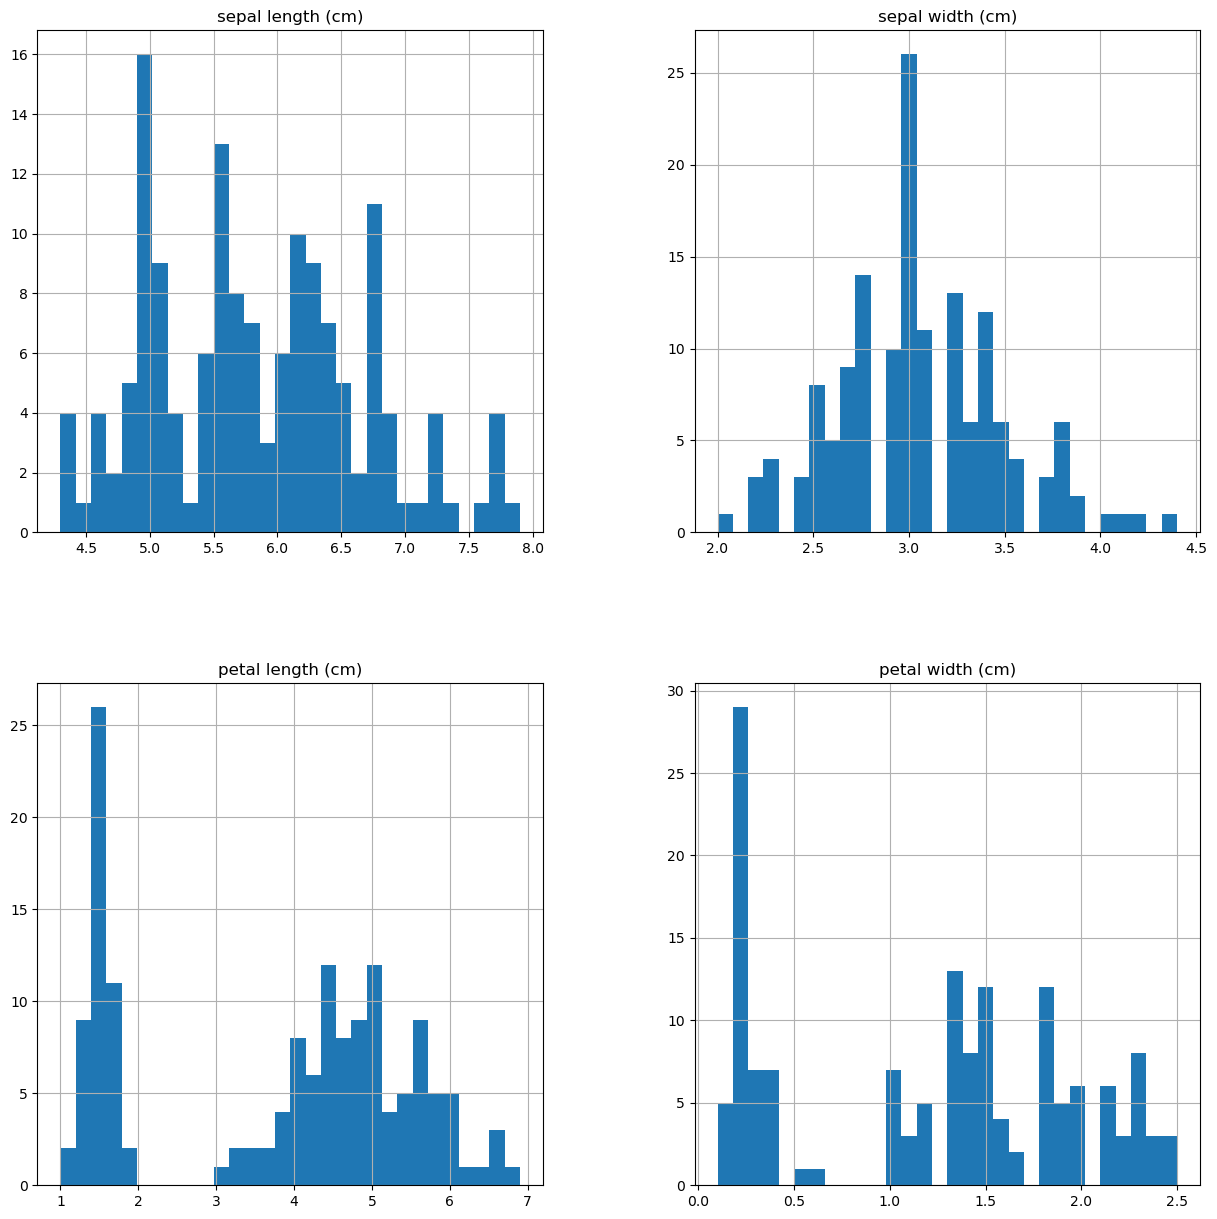

In [44]:
# Analiza rozkładów  ile czego
# Histogramy dla zmiennych ilościowych

iris_df[predictors].hist(bins=30, figsize=(15,15))
plt.show()

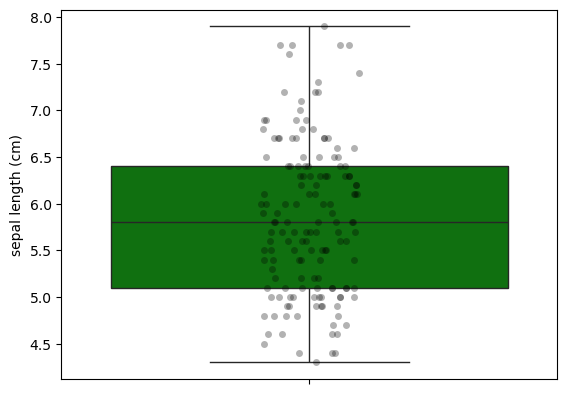

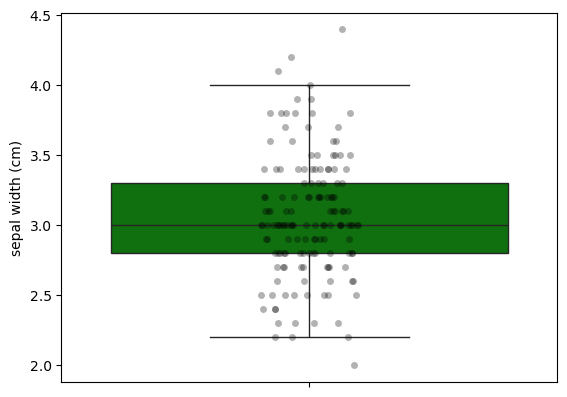

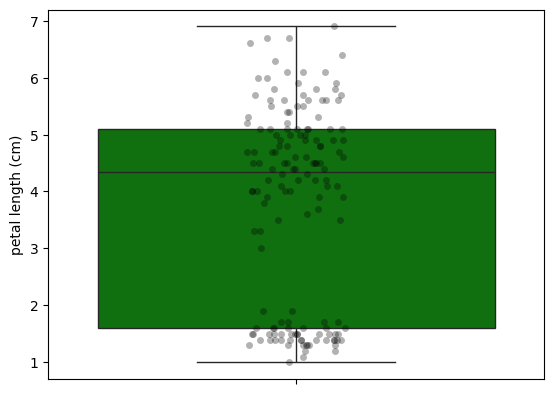

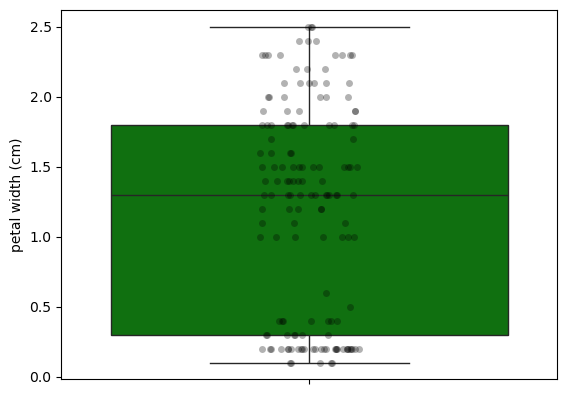

In [46]:
# Wykresy ramka-wąsy analiza pod kątem wartości odstających
for var in predictors:
    
    sns.boxplot(data=iris_df, y=var, fliersize=0, color='green')
    sns.stripplot(data=iris_df, y=var, jitter=0.1, alpha=0.3, color='k')
    plt.show()

W kodzie musieliśmy "na sztywno" wpisywać nazwę ramki danych być może lepiej jest skorzystać z bardziej uniwersalnej funkcji?

In [50]:
def plot_box_strip(df, variables, hue=None):
    """
    Tworzy wykresy pudełkowe z nakładającymi się wykresami strip dla podanych zmiennych.
    
    Parametry:
    - df: DataFrame zawierający dane
    - variables: lista nazw kolumn dla zmiennych ilościowych
    - hue: opcjonalna zmienna grupująca (kategoryczna)
    """
    for var in variables:
        plt.figure(figsize=(8, 6))
        
        # Wykres pudełkowy
        sns.boxplot(data=df, y=var, x=hue, fliersize=0, color='green')

        # Wykres strip
        sns.stripplot(data=df, y=var, x=hue, jitter=0.1, alpha=0.3, color='k', dodge=True if hue else False)
        
        plt.title(f'Wykres pudełkowy: {var}')
        plt.xlabel(hue if hue else '')
        plt.ylabel(var)
        plt.show()

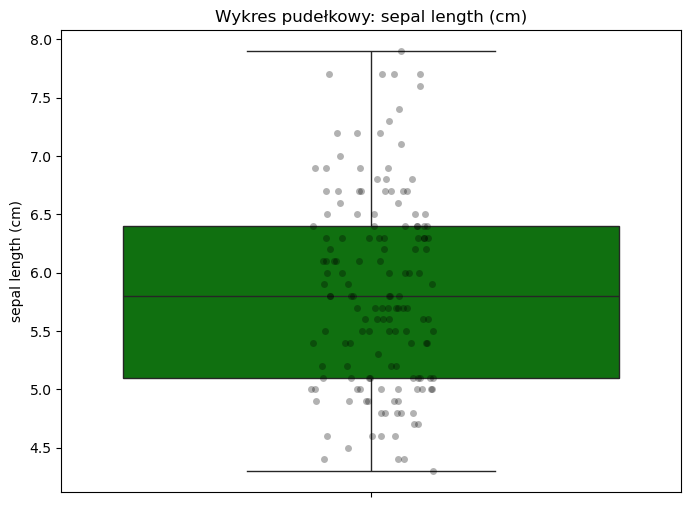

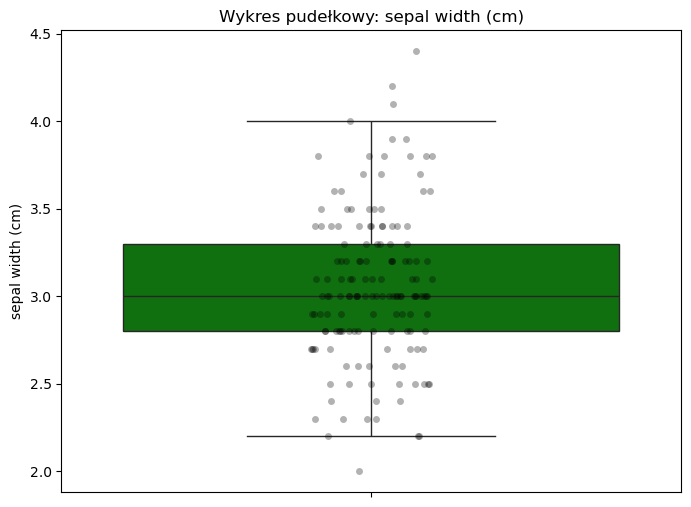

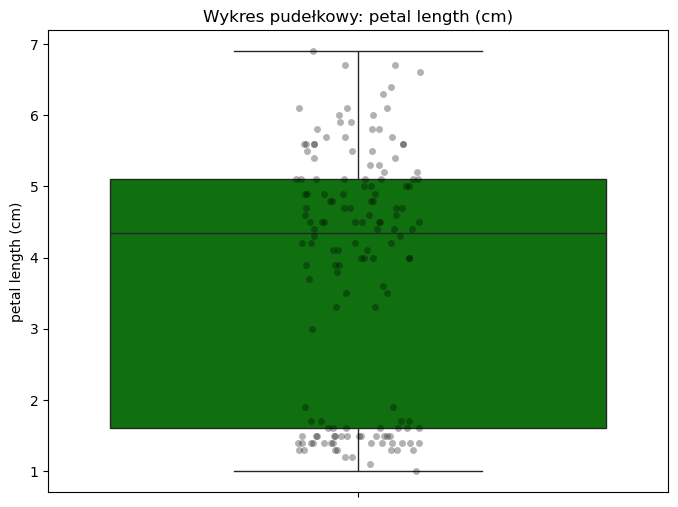

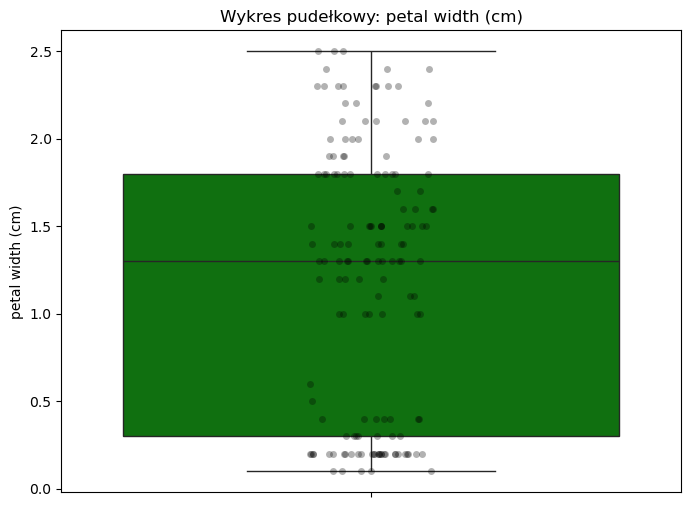

In [52]:
plot_box_strip(iris_df,predictors)

In [54]:
# Podsumowanie podstwowych statystyk
iris_df[predictors].describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [58]:
# graficzna analiza rozkładu zmiennej jakościowej
def plot_categorical_bars(df, categorical_vars):
    """
    Tworzy wykresy słupkowe dla każdej zmiennej jakościowej w podanej ramce danych.

    Parametry:
    - df: DataFrame zawierający zmienne jakościowe
    - categorical_vars: lista nazw kolumn zawierających zmienne jakościowe
    """
    for var in categorical_vars:
        plt.figure(figsize=(6, 4))
        df[var].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
        plt.title(f'Liczność kategorii dla zmiennej: {var}')
        plt.xlabel(var)
        plt.ylabel('Liczność')
        plt.xticks(rotation=45)  # Obrót etykiet kategorii dla czytelności
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.show()

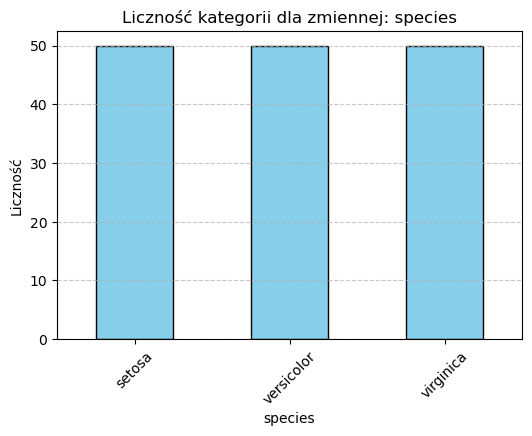

In [60]:
plot_categorical_bars(iris_df, additional)

In [86]:
# Tabela liczności dla zmiennych jakościowych

def categorical_summary(df, column):
    """
    Tworzy tabelę liczności dla jednej zmiennej jakościowej.
    
    Parametry:
    - df: DataFrame zawierający dane
    - column: nazwa kolumny jakościowej
    
    Zwraca:
    - DataFrame z licznością i procentowym udziałem kategorii
    """
    counts = df[column].value_counts(dropna=False)
    labels = counts.index.fillna("Brak danych").astype(str)
    percentages = (counts / counts.sum() * 100).round(2)
    
    return pd.DataFrame({"Etykieta": labels, "Liczność": counts.values, "Procent": percentages.values})

In [88]:
for var in additional:
    tab = categorical_summary(iris_df, var)
    print(tab)

     Etykieta  Liczność  Procent
0      setosa        50    33.33
1  versicolor        50    33.33
2   virginica        50    33.33


## Zrozumieliśmy dane teraz zaczynamy ich czyszczenie
### Na początek wartości odstające

1. Wartości spoza zakresu "obcinamy" do granic uznanych za typowe
2. Wartości ekstrematnie nietypowe być może będziemy musieli usunąć z analizy

In [90]:
# capping_method='iqr' - metoda oparta na rozstępie kwartylowym
# fold=1.5 - parametr sterujacy szerokocią przycinania 
# tail='both' → obcina wartości odstające zarówno z lewej (dolne wartości), jak i z prawej strony (górne wartości).

winsorizer = Winsorizer(capping_method='iqr', fold=1.5, tail='both')
iris_df[predictors] = winsorizer.fit_transform(iris_df[predictors])


3. Sprawdźmy efekt

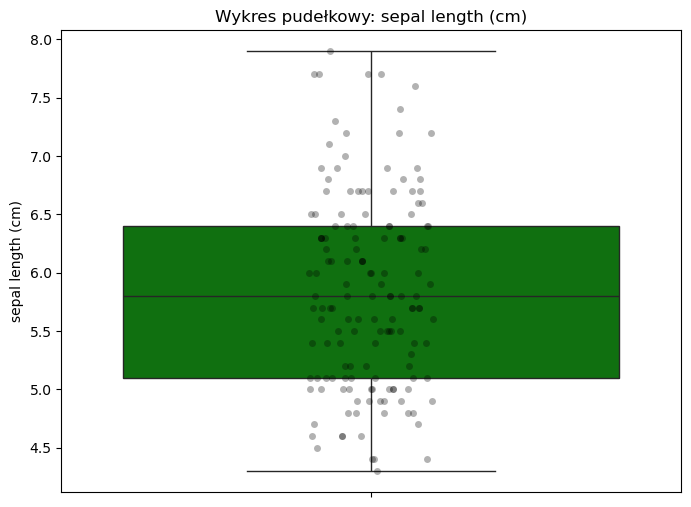

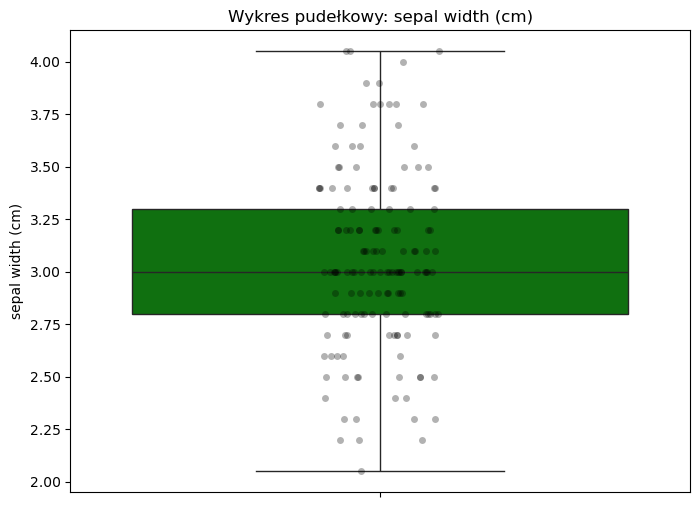

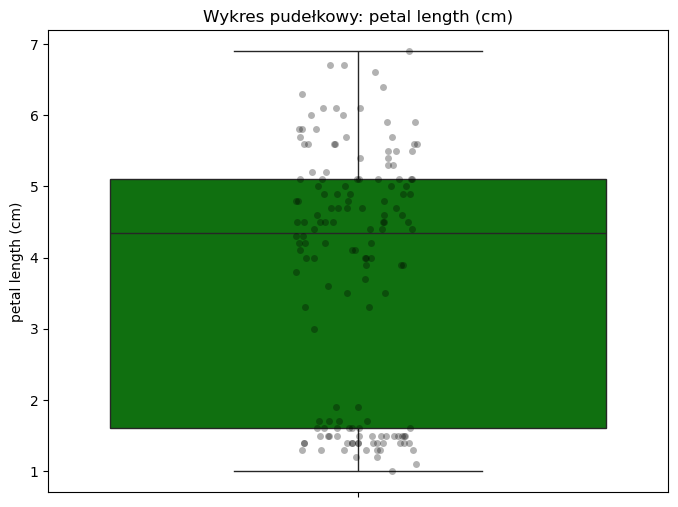

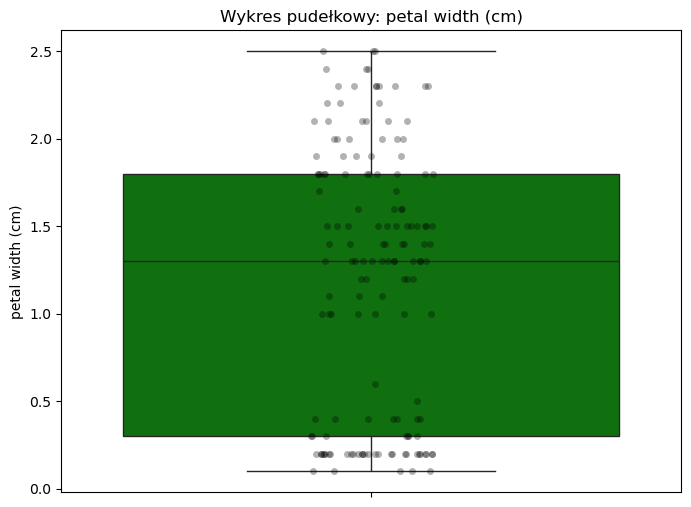

In [68]:
plot_box_strip(iris_df,predictors)

## Sprawdźmy powiązania pomiędzy zmiennymi

1. Korelacje między zmiennymi - za pomocą korelacji Spearmana
2. Graficzne przedstawienie za pomocą mapy ciepła
3. Powiązania pomiędzy zmiennymi za pomocą wykresu rozrzutu

In [92]:
# Obliczanie macierzy korelacji rang Spearmana zakłada liniowość danych
spearman_corr_matrix = iris_df[predictors].corr(method='spearman')

spearman_corr_matrix.head(4)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.166871,0.881898,0.834289
sepal width (cm),-0.166871,1.000000,-0.309636,-0.289184
petal length (cm),0.881898,-0.309636,1.000000,0.937667
petal width (cm),0.834289,-0.289184,0.937667,1.000000


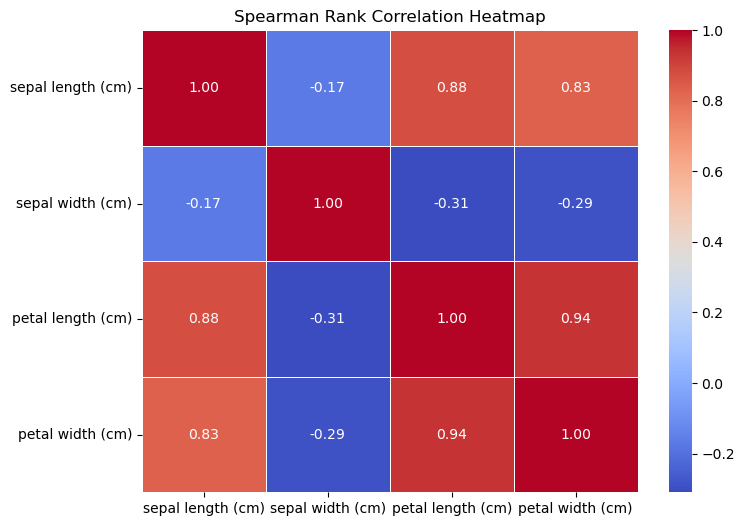

In [106]:
# Tworzenie mapy ciepła w teorii powinniśmy coś z tym zrobić
plt.figure(figsize=(8, 6))
sns.heatmap(spearman_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# Tytuł wykresu
plt.title("Spearman Rank Correlation Heatmap")

# Wyświetlenie wykresu
plt.show()

In [108]:
# Wykres rozrzutu
def scatter_plot(df, variables, hue=None):
    """
    Tworzy wykres rozrzutu dla podanych zmiennych.
    
    Parametry:
    - df: DataFrame z danymi
    - variables: lista 2 nazw kolumn (x, y)
    - hue: opcjonalna zmienna jakościowa do kolorowania punktów
    """
    if len(variables) != 2:
        raise ValueError("Lista 'variables' musi zawierać dokładnie 2 zmienne (x i y).")
    
    x, y = variables
    plt.figure(figsize=(8, 6))
    
    if hue:
        sns.scatterplot(data=df, x=x, y=y, hue=hue, palette="Set1", alpha=0.7)
        plt.legend(title=hue)
    else:
        sns.scatterplot(data=df, x=x, y=y, alpha=0.7)  # Bez hue i palette

    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(f'Wykres rozrzutu: {x} vs {y}')
    plt.show()

In [100]:
print(predictors)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


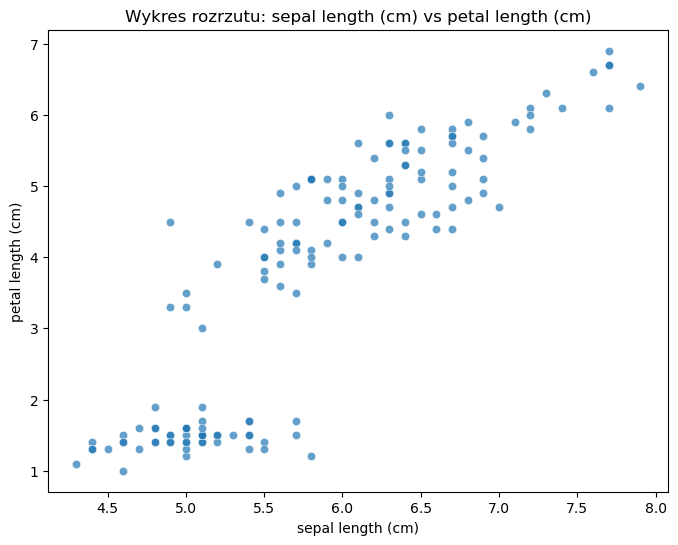

In [102]:
scatter_plot(iris_df, ['sepal length (cm)', 'petal length (cm)'])

W przypadku mniejszej listy zmiennych możemy przedstawić wszystkie zmienne na zbiorczym wykresie

In [110]:
def scatter_matrix_plot(df, variables, hue=None):
    """
    Tworzy macierzowy wykres rozrzutu dla podanych zmiennych ilościowych.
    
    Parametry:
    - df: DataFrame zawierający dane
    - variables: lista nazw kolumn dla zmiennych ilościowych
    - hue: opcjonalna zmienna jakościowa do kolorowania punktów
    """
    sns.pairplot(df, vars=variables, hue=hue, palette="Set1" if hue else None, corner=True)
    plt.show()

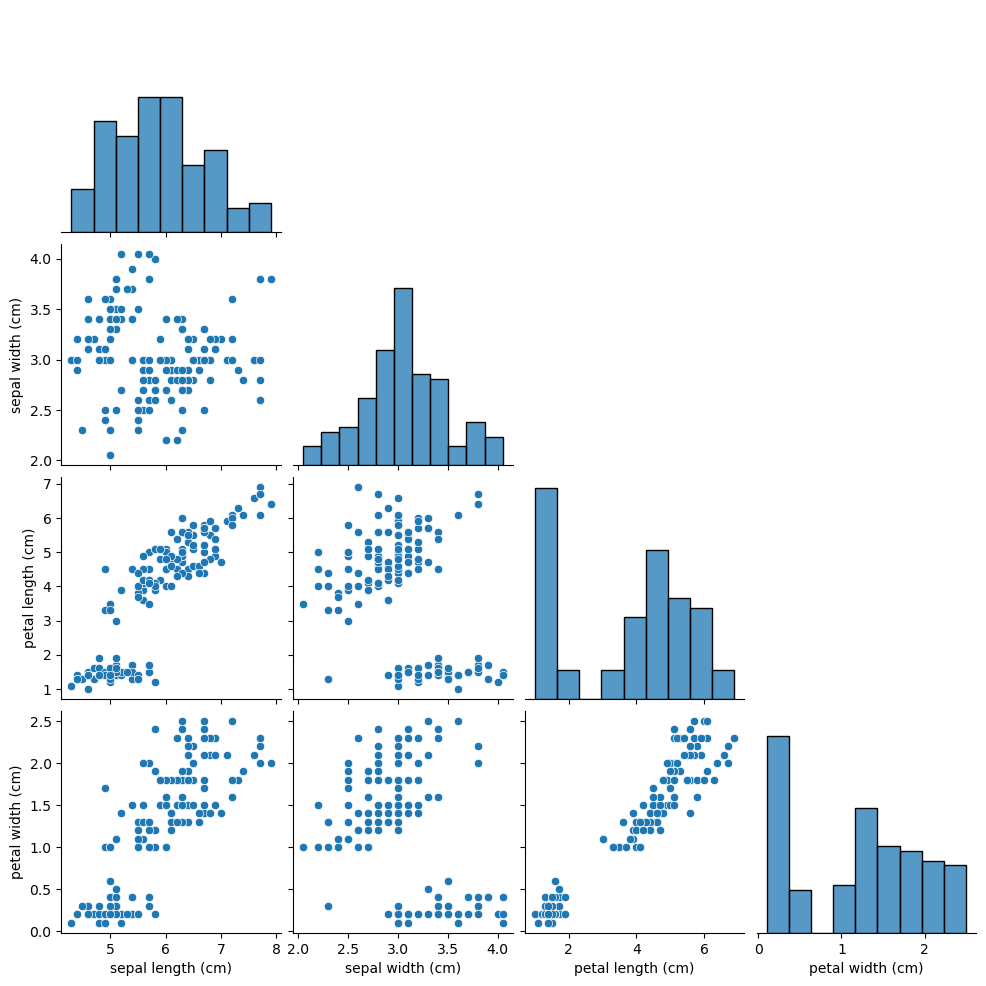

In [112]:
scatter_matrix_plot(iris_df,predictors)

### Analiza skupień wymaga przeskalowania danych do wspólnego zakresu
1. Wynik skalowania umieścimy w nowej ramce danych
2. Zobaczymy jak wyglądają rozkłady zmiennych po skalowaniu

In [116]:
# Skalujemy wartości predyktorów
# Przed wykonaniem skalowania wykonamy kopię ramki danych "scaled"
scaled_iris_df = iris_df.copy()

min_max_scaler = MinMaxScaler()
scaled_iris_df[predictors]= min_max_scaler.fit_transform(scaled_iris_df[predictors])

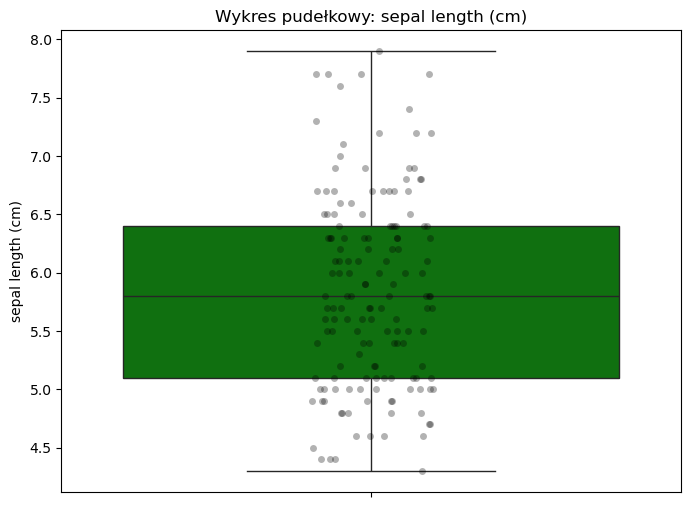

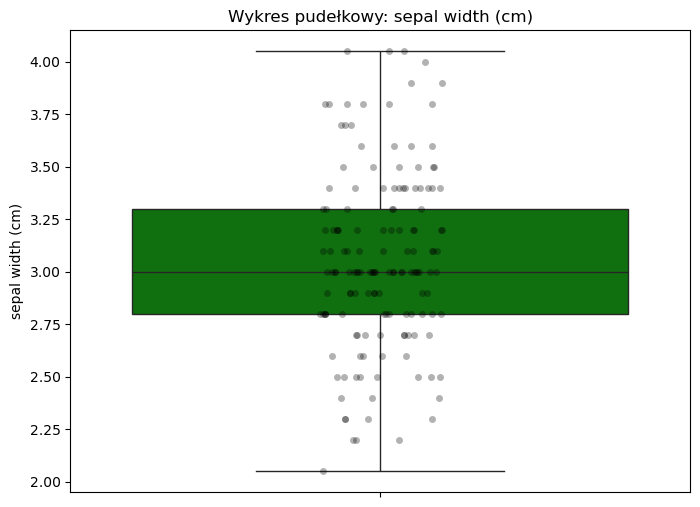

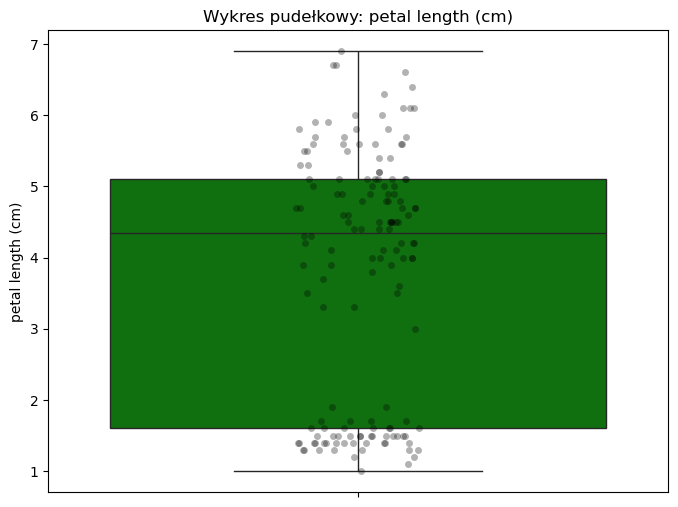

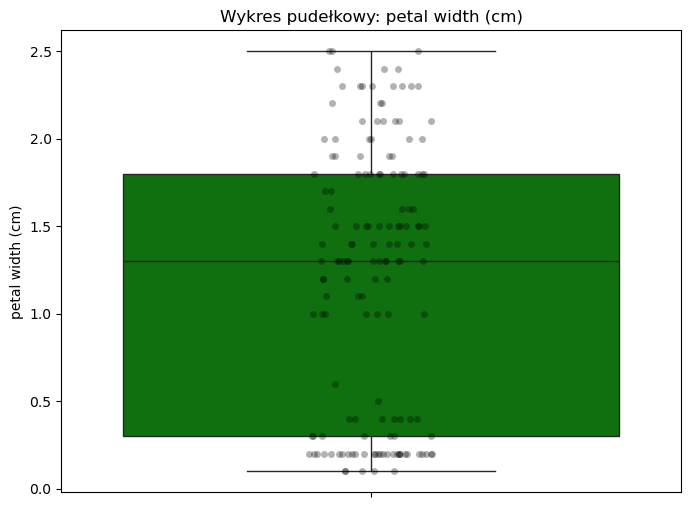

In [118]:
plot_box_strip(iris_df,predictors)

### Zbudujemy i ocenimy pierwszy model

1. W modelu k-średnich podajemy z góry liczbę skupień - przyjmijmy wstępnie że są 3 skupienia
2. Budujemy model i od razu przypisujemy do kolumny z danymi predykcję modelu
3. Predykcję zapisujemy zaróno do oryginalnych danych jak i do przeskalowanych danych

Ewentualne ostrzeżenie możemy wyłączyć za pomocą poniższego kodu

**import warnings**<BR>
**warnings.simplefilter(action='ignore', category=UserWarning)**

In [120]:
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)

#podaj liczbę skupień
n_clusters= 3

kmeans_model = KMeans(n_clusters=n_clusters, random_state=seed)

#wykonaj model i przypisz predykcję do tablicy z wynikami
kmeans_model_classes = kmeans_model.fit_predict(scaled_iris_df[predictors])

# zapisz predykcję do kolumny w ramce danych
iris_df['predicted_class'] = kmeans_model_classes

# zapisz predykcję do kolumny w ramce danych wystandaryzowanych
scaled_iris_df['predicted_class'] = kmeans_model_classes

In [122]:
iris_df.head(45)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,predicted_class
0,5.1,3.50,1.4,0.2,setosa,1
1,4.9,3.00,1.4,0.2,setosa,1
2,4.7,3.20,1.3,0.2,setosa,1
3,4.6,3.10,1.5,0.2,setosa,1
4,5.0,3.60,1.4,0.2,setosa,1
5,5.4,3.90,1.7,0.4,setosa,1
6,4.6,3.40,1.4,0.3,setosa,1
7,5.0,3.40,1.5,0.2,setosa,1
8,4.4,2.90,1.4,0.2,setosa,1
9,4.9,3.10,1.5,0.1,setosa,1


### Chcemy teraz zrozumieć uzyskane wyniki

1. Oceniamy liczbę elementów w poszczególnych skupieniach (małe liczności mogą świadczyć o błędnym modelu)
2. Badamy średnie wartości zmiennych w skupieniach (brak zróżnicowania zmiennych może być podstawą do jej eliminacji)
3. Prezentujemy śerednie wartości wyskalowanych zmiennych na wykresie

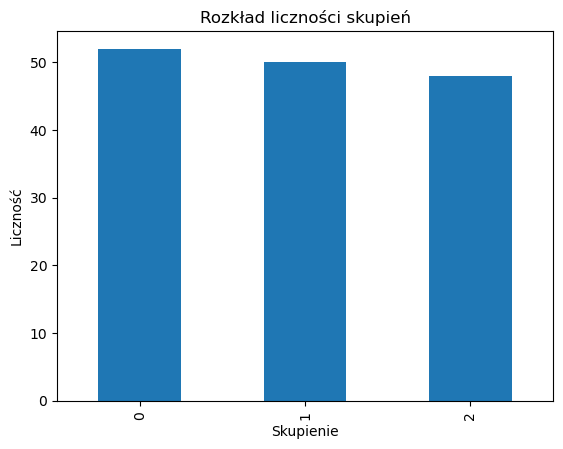

In [124]:
# Tworzenie wykresu słupkowego
iris_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

In [126]:
# Grupowanie danych po segmencie (dane surowe) i obliczenie średnich
means = iris_df.groupby("predicted_class")[predictors].mean()

means.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
predicted_class,,,,
0,5.830769,2.668269,4.342308,1.378846
1,5.006000,3.417000,1.462000,0.246000
2,6.729167,3.093750,5.516667,1.997917


In [128]:
# Grupowanie danych po segmencie (dane wyskalowane) i obliczenie średnich
means_scaled = scaled_iris_df.groupby("predicted_class")[predictors].mean()

means_scaled.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
predicted_class,,,,
0,0.425214,0.309135,0.566493,0.532853
1,0.196111,0.683500,0.078305,0.060833
2,0.674769,0.521875,0.765537,0.790799


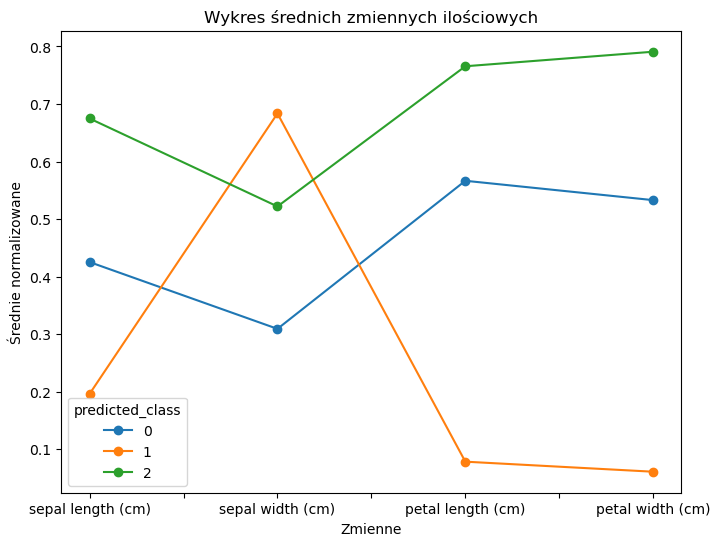

In [130]:
# Wykres dla średnich znormalizowanych
means_scaled.T.plot(marker="o", linestyle="-", figsize=(8, 6))

# Opisy osi i tytuł
plt.xlabel("Zmienne")
plt.ylabel("Średnie normalizowane")
plt.title("Wykres średnich zmiennych ilościowych")

plt.show()

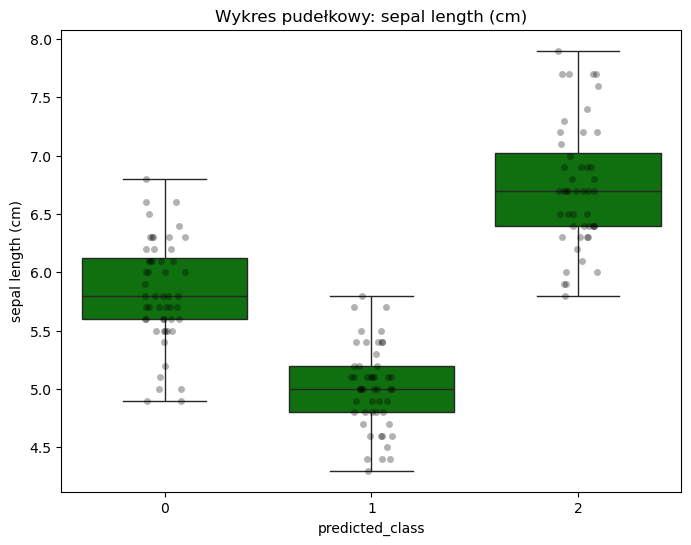

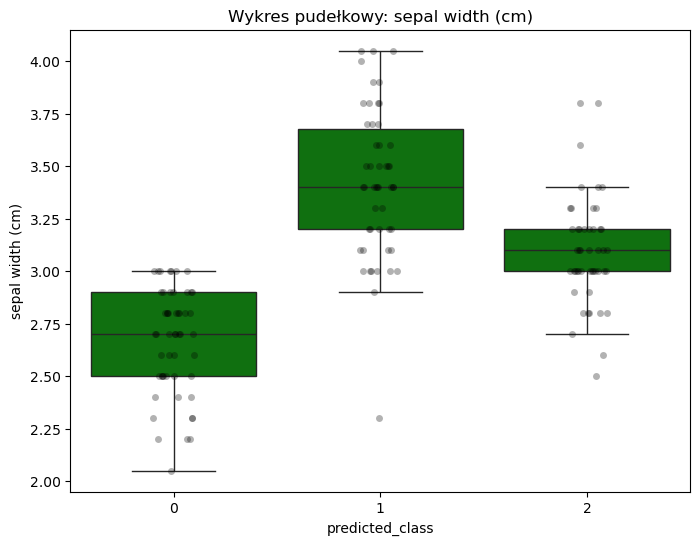

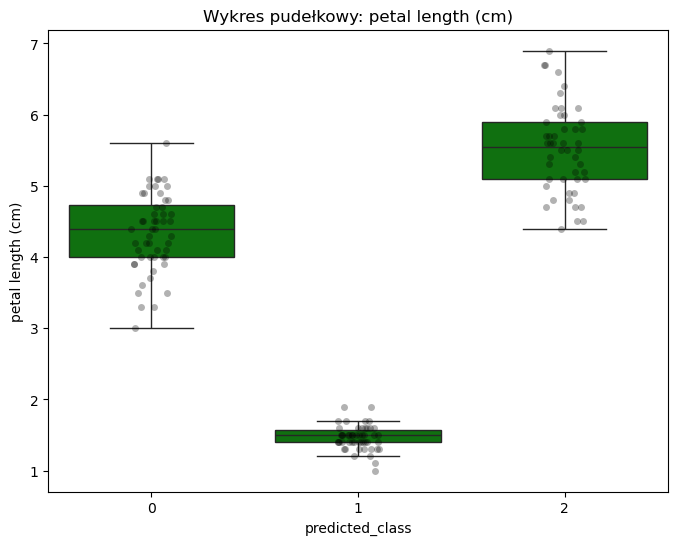

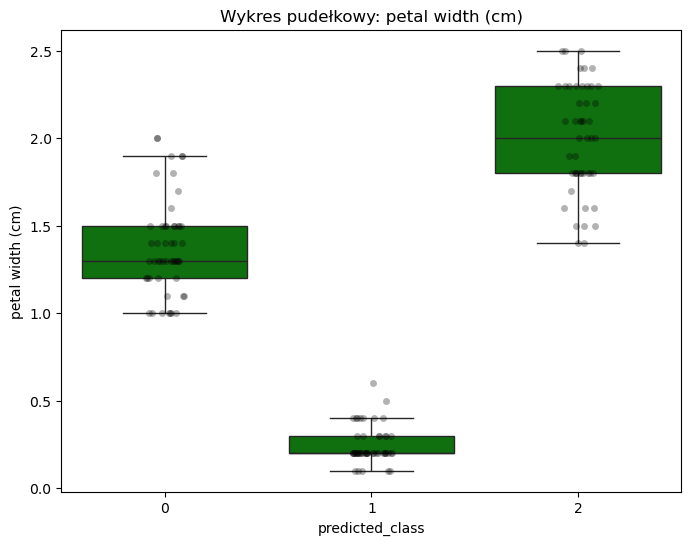

In [140]:
# Wykres ramkowy dla zmiennych w przekroju segmentów
plot_box_strip(iris_df,predictors,hue="predicted_class")

### Możemy też sprawdzić jak się mają wyniki do zmiennej "Species" będącej poza analizą

In [132]:
# Tworzenie tabeli kontyngencji
contingency_table = pd.crosstab(iris_df["predicted_class"],iris_df["species"])

contingency_table.head()

species,setosa,versicolor,virginica
predicted_class,,,
0,0,41,11
1,50,0,0
2,0,9,39


### Spróbujmy ocenić model

1. Wskaźnik sylwetki
2. Wykres sylwetki

Blisko 1 → Bardzo dobre klastrowanie, obiekty dobrze dopasowane do swoich klastrów <BR>
Około 0.5 → Średnia jakość klastrowania, niektóre punkty mogą być źle przypisane <BR>
Blisko 0 → Punkty leżą na granicy klastrów, możliwe nakładanie się klas <BR>
Wartości ujemne → Punkty są przypisane do złych klastrów <BR>

In [134]:
from sklearn.metrics import silhouette_score

# Obliczenie wskaźnika sylwetki
silhouette_avg = silhouette_score(scaled_iris_df[predictors], scaled_iris_df["predicted_class"])

print(f"Wartość wskaźnika sylwetki: {silhouette_avg:.4f}")

Wartość wskaźnika sylwetki: 0.4807


In [136]:
from sklearn.metrics import silhouette_samples, silhouette_score

def plot_silhouette(data, cluster_column, predictors):
    """
    Tworzy wykres wskaźnika sylwetki dla danych po klasteryzacji.

    Parametry:
    - data: DataFrame zawierający przeskalowane zmienne predykcyjne oraz kolumnę z etykietami klastrów
    - cluster_column: nazwa kolumny zawierającej etykiety klas
    - predictors: lista nazw kolumn zawierających cechy używane do klasteryzacji
    """

    # Obliczenie wartości wskaźnika sylwetki dla każdego punktu
    silhouette_vals = silhouette_samples(data[predictors], data[cluster_column])

    # Pobranie unikalnych etykiet klas
    clusters = np.unique(data[cluster_column])

    # Tworzenie wykresu
    plt.figure(figsize=(8, 6))

    y_lower = 0
    for cluster in clusters:
        # Pobranie wartości sylwetki dla danego klastra
        cluster_vals = silhouette_vals[data[cluster_column] == cluster]
        cluster_vals.sort()

        y_upper = y_lower + len(cluster_vals)
        plt.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_vals, label=f"Skupienie {cluster}")

        y_lower = y_upper

    # Rysowanie średniego wskaźnika sylwetki jako pionowej linii
    silhouette_avg = silhouette_score(data[predictors], data[cluster_column])
    plt.axvline(x=silhouette_avg, color="red", linestyle="--", label="Średnia sylwetka")

    # Opisy osi i tytuł
    plt.xlabel("Wartość wskaźnika sylwetki")
    plt.ylabel("Obserwacje w skupieniach")
    plt.title("Wykres wskaźnika sylwetki dla skupień")

    # Legenda
    plt.legend()

    # Wyświetlenie wykresu
    plt.show()

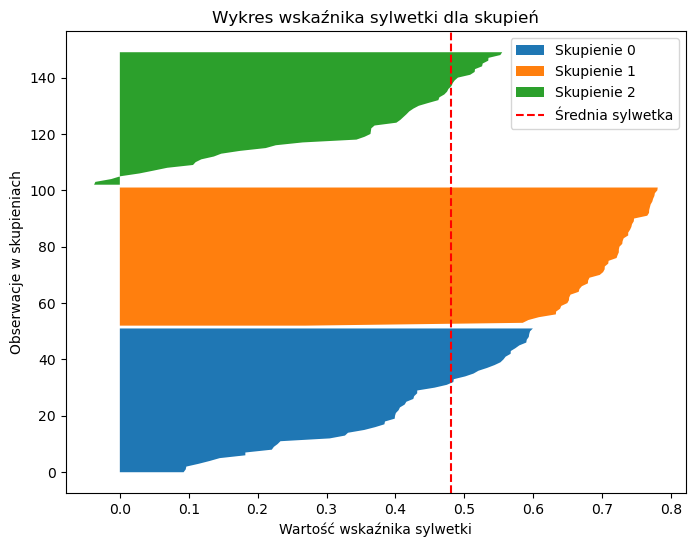

In [138]:
plot_silhouette(scaled_iris_df,"predicted_class",predictors)

### W naszym zbiorze istnieje wartość "rzeczywista" jest nią nazwa odmiany, możemy zatem ocenić zgodność wyniku z odmianą

1. Obliczmy wystandaryzowany wskaźnik Randa

1.0 → Idealne dopasowanie do rzeczywistych etykiet klas (klastry są idealnie zgodne z prawdziwymi grupami) <BR>
0.0 → Klasyfikacja losowa (klastry nie mają żadnej zgodności z prawdziwymi etykietami) <BR>
Wartości ujemne → Gorsze niż losowe przypisanie (bardzo źle dobrane klastry) <BR>

In [146]:
from sklearn.metrics import adjusted_rand_score

# Obliczenie wskaźnika ARI
ari_score = adjusted_rand_score(scaled_iris_df["species"], scaled_iris_df["predicted_class"])

print(f"Wystandaryzowany wskaźnik Randa (ARI): {ari_score:.4f}")

Wystandaryzowany wskaźnik Randa (ARI): 0.6757


### Być może inna liczba skupień pozwoliłaby uzyskać lepszy wynik?

1. Zbudujemy wiele modeli dla różnych wartości k
2. Wynik porównamy za pomocą wykresu osypiska dla wartości inercji
3. Sprawdzimy też wartości indeksu sylwetki

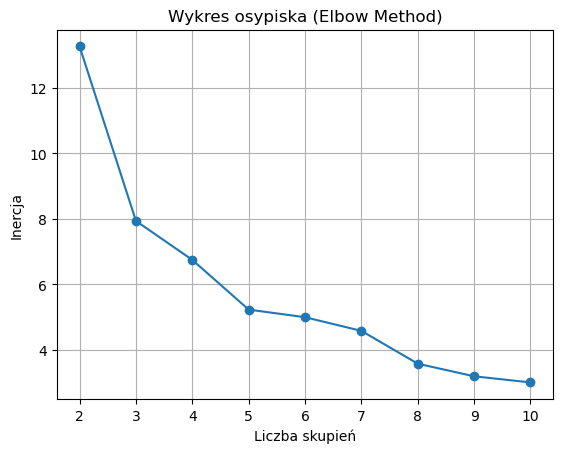

,Liczba skupień,Wskaźnik sylwetki
0,2,0.621373
1,3,0.480666
2,4,0.400021
3,5,0.347961
4,6,0.346485
5,7,0.286072
6,8,0.331617
7,9,0.324623
8,10,0.305430


In [148]:
# Zakres liczby skupień
cluster_range = range(2, 11)

# Listy do zapisania wyników
inertia_values = []
silhouette_values = []

# Pętla dla różnej liczby skupień
for k in cluster_range:
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(scaled_iris_df[predictors])
    
    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(scaled_iris_df[predictors], labels))
    

# Wykres osypiska (Elbow Method)
plt.plot(cluster_range, inertia_values, marker="o", linestyle="-")
plt.xlabel("Liczba skupień")
plt.ylabel("Inercja")
plt.title("Wykres osypiska (Elbow Method)")
plt.grid(True)
plt.show()

# Tabelka wskaźników sylwetki
df_silhouette = pd.DataFrame({"Liczba skupień": cluster_range, "Wskaźnik sylwetki": silhouette_values})
df_silhouette.head(10)

### Co jeszcze można zrobić?

1. Zmienne pochodne - pole płatka i pole działki
2. Eliminacja zmiennych nadmiernie skorelowanych
3. Inne ustawienia metody k-średnich
4. Użycie innego algorytmu grupowania - na przykład aglomeracji, DBSCan, sieci neuronowe, GMM

Sprawdźmy jakie ustawienia (hiperparametry) oferuje metoda KMeans
https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

### Dodatkowe miary oceny modelu

**Calinski-Harabasz Score (wartości większe = lepsze) – mierzy stosunek wariancji między klastrami do wariancji wewnątrz klastrów**

Jest to stosunek wariancji międzyklastrowej do wariancji wewnątrzklastrowej. ***Brak uniwersalnych progów*** ale w praktyce:<BR>
* ≥ 500 – bardzo dobrze oddzielone klastry (dla dużych zbiorów danych).
* 100-500 – dobra klasteryzacja.
* < 100 – klastry są słabo oddzielone.
* Bliskie 0 – bardzo słaba klasteryzacja, przypomina losowy podział.

**Davies-Bouldin Score (wartości niższe = lepsze) – mierzy, jak bardzo klastry są od siebie oddzielone** Interpretacja:
* Blisko 0 – bardzo dobrze oddzielone klastry.
* 0.5 – 1.5 – dobra jakość klastrów.
* \> 2 – klastry zaczynają się nakładać i są źle rozdzielone.
* \> 3 – bardzo słaba klasteryzacja.

Wartość bliska 0 oznacza dobrze oddzielone klastry. Jednak dla różnych zbiorów danych różne wartości mogą być uznawane za dobre.     
    

In [150]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

# Obliczenie wskaźników
calinski_harabasz = calinski_harabasz_score(scaled_iris_df[predictors], scaled_iris_df["predicted_class"])
davies_bouldin = davies_bouldin_score(scaled_iris_df[predictors], scaled_iris_df["predicted_class"])

# Wyświetlenie wyników
print(f"Wartość wskaźnika Calinskiego-Harabasza: {calinski_harabasz:.4f}")
print(f"Wartość wskaźnika Daviesa-Bouldina: {davies_bouldin:.4f}")

Wartość wskaźnika Calinskiego-Harabasza: 324.5456
Wartość wskaźnika Daviesa-Bouldina: 0.8053


### Wizualizacja i ocena jakości segmentacji

Po przeprowadzeniu segmentacji chcemy sprawdzić, czy nasze grupy są dobrze rozdzielone. Ponieważ mamy wiele cech, trudno to zobaczyć bezpośrednio, dlatego stosujemy redukcję wymiarów – PCA (analiza głównych składowych) lub t-SNE. Te metody pozwalają nam przedstawić dane na wykresie 2D, zachowując jak najwięcej informacji o strukturze klastrów. Jeśli klastry są dobrze oddzielone, oznacza to, że segmentacja przebiegła poprawnie i rzeczywiście znaleźliśmy grupy o różnych cechach.

In [183]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
def visualize_clusters(df, predictors, cluster_col, method='PCA'):
    """
    Wizualizuje klastry w 2D przy użyciu PCA lub t-SNE, dodając centroidy.
    
    Parametry:
    - df: DataFrame zawierający dane
    - predictors: lista kolumn do redukcji wymiarów
    - cluster_col: nazwa kolumny zawierającej przypisane klastry
    - method: 'PCA' lub 't-SNE' (domyślnie 'PCA')
    """
    
    # Redukcja wymiarów
    if method == 'PCA':
        reducer = PCA(n_components=2)
        x_label, y_label, title = "Pierwsza składowa PCA", "Druga składowa PCA", "Klastry w PCA"
    elif method == 't-SNE':
        reducer = TSNE(n_components=2, perplexity=30, random_state=42)
        x_label, y_label, title = "Pierwszy wymiar t-SNE", "Drugi wymiar t-SNE", "Klastry w t-SNE"
    else:
        raise ValueError("Metoda musi być 'PCA' lub 't-SNE'")
    
    # Przekształcenie danych
    X_transformed = reducer.fit_transform(df[predictors])
    
    # Dodanie centroidów – obliczamy średnie wartości dla każdego klastra
    df_transformed = df.copy()
    df_transformed['X1'] = X_transformed[:, 0]
    df_transformed['X2'] = X_transformed[:, 1]
    
    centroids = df_transformed.groupby(cluster_col)[['X1', 'X2']].mean()
    
    # Tworzenie wykresu
    plt.figure(figsize=(6, 5))
    sns.scatterplot(x='X1', y='X2', hue=cluster_col, palette='Set1', data=df_transformed, alpha=0.7)
    
    # Dodanie centroidów jako czarnych "X"
    plt.scatter(centroids['X1'], centroids['X2'], marker="X", s=200, c="black", label="Centroidy")
    
    # Opisy wykresu
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.legend(title="Skupienie")
    plt.show()

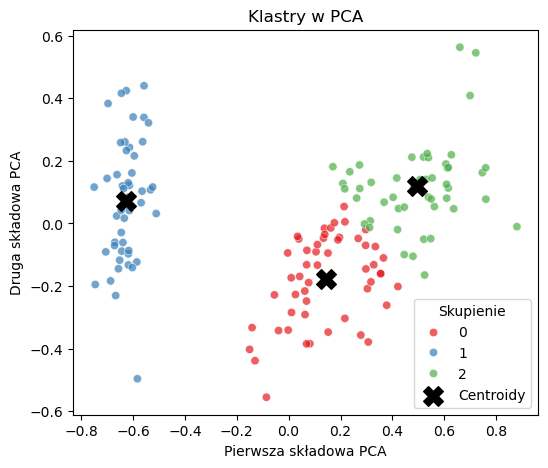

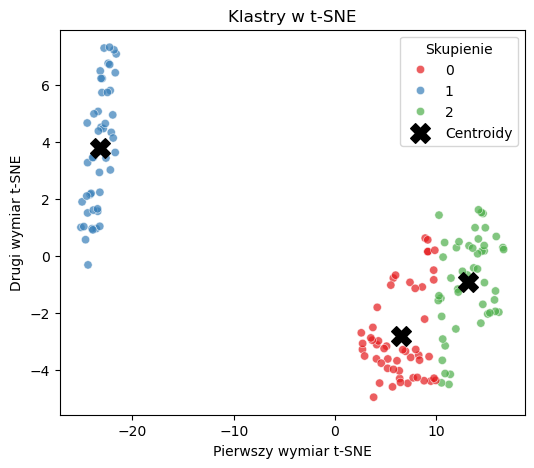

In [185]:
visualize_clusters(scaled_iris_df, predictors, 'predicted_class', method='PCA')
visualize_clusters(scaled_iris_df, predictors, 'predicted_class', method='t-SNE')